# Integrated Data Science Pipeline: Python Logic, Data Engineering & Exploratory Analysis

**Author: HARPREET SINGH**

[![Python](https://img.shields.io/badge/Python-3.10%2B-blue)](https://www.python.org/)
[![Pandas](https://img.shields.io/badge/Pandas-data%20wrangling-150458)](https://pandas.pydata.org/)
[![Status](https://img.shields.io/badge/Status-Portfolio%20Project-success)]()

## Project overview

A reproducible, end-to-end portfolio project demonstrating core Python logic, Monte Carlo simulation, structured data manipulation with pandas, synthetic dataset generation, exploratory data analysis (EDA), statistical summaries, visual storytelling, and exportable project artefacts.

> **Data transparency:** the farm, livestock and housing records in this repository are illustrative/synthetic examples generated by code. The housing data is inspired by common residential-property features; it is **not** the official Ames Housing dataset and must not be interpreted as real market evidence.

## Learning objectives

- Build reusable, validated Python functions and decision rules.
- Explain uncertainty through a seeded Monte Carlo experiment.
- Create, inspect, compare and export pandas Series and DataFrames.
- Generate a reproducible synthetic housing dataset.
- Compare distributions, group-level outcomes and feature correlations.
- Communicate findings through tables, charts and a process diagram.

## Pipeline at a glance

`Python logic → simulation → pandas data preparation → synthetic housing data → EDA → exported datasets & figures`

## Contents

1. Environment and reproducibility
2. Python fundamentals and decision matrix
3. Blackjack-inspired Monte Carlo simulation
4. Pandas data engineering and comparison tables
5. Synthetic housing dataset and quality checks
6. EDA: descriptive statistics, comparisons, charts and correlations
7. Findings, limitations and exported artefacts

## 1. Environment and reproducibility

Install dependencies from `requirements.txt`. A fixed random seed makes the generated examples reproducible. The notebook creates the `data/` and `figures/` folders if they do not already exist.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "figures"
REPORTS_DIR = PROJECT_ROOT / "reports"
for folder in (DATA_DIR, FIGURES_DIR, REPORTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 10, "savefig.dpi": 160})

print(f"Python data-science environment ready. pandas={pd.__version__}, numpy={np.__version__}")
print(f"Project root: {PROJECT_ROOT.resolve()}")

Python data-science environment ready. pandas=2.2.3, numpy=2.3.5
Project root: /mnt/data/data-science-foundations-to-eda


## 2. Python fundamentals and decision matrix

The first module uses small, testable functions. Inputs are validated so that invalid values fail clearly rather than silently producing misleading results.

In [2]:
def determine_sign(value: float) -> int:
    """Return 1 for positive, -1 for negative, and 0 for zero."""
    if not isinstance(value, (int, float, np.number)) or not np.isfinite(value):
        raise ValueError("value must be a finite number")
    return 1 if value > 0 else (-1 if value < 0 else 0)

sign_examples = pd.DataFrame({"input": [-55.8, 0, 128.4, -0.01]})
sign_examples["sign"] = sign_examples["input"].map(determine_sign)
display(sign_examples)

def distribute_items(total: int, people: int = 4) -> dict:
    """Return equal allocation and remainder for a non-negative item count."""
    if not isinstance(total, int) or total < 0:
        raise ValueError("total must be a non-negative integer")
    if not isinstance(people, int) or people <= 0:
        raise ValueError("people must be a positive integer")
    return {"total_items": total, "people": people,
            "items_each": total // people, "remainder": total % people}

allocation_table = pd.DataFrame([distribute_items(143, 4), distribute_items(1, 4)])
display(allocation_table)

def weather_readiness(has_umbrella: bool, rainfall_mm: float,
                      has_hood: bool, is_workday: bool) -> bool:
    """Illustrative rule: umbrella, or light rain with hood, or dry workday."""
    if rainfall_mm < 0:
        raise ValueError("rainfall_mm cannot be negative")
    return bool(has_umbrella or (rainfall_mm < 6 and has_hood)
                or (rainfall_mm == 0 and is_workday))

weather_cases = pd.DataFrame([
    {"Umbrella": False, "Rainfall_mm": 4.5, "Hood": True, "Workday": True},
    {"Umbrella": False, "Rainfall_mm": 9.2, "Hood": True, "Workday": False},
    {"Umbrella": True, "Rainfall_mm": 18.0, "Hood": False, "Workday": True},
    {"Umbrella": False, "Rainfall_mm": 0.0, "Hood": False, "Workday": True},
])
weather_cases["Safe_To_Go"] = weather_cases.apply(
    lambda r: weather_readiness(r.Umbrella, r.Rainfall_mm, r.Hood, r.Workday), axis=1
)
display(weather_cases)

,input,sign
0,-55.80,-1
1,0.00,0
2,128.40,1
3,-0.01,-1


,total_items,people,items_each,remainder
0,143,4,35,3
1,1,4,0,1


,Umbrella,Rainfall_mm,Hood,Workday,Safe_To_Go
0,False,4.5,True,True,True
1,False,9.2,True,False,False
2,True,18.0,False,True,True
3,False,0.0,False,True,True


### Decision-rule diagram

The diagram summarizes the illustrative weather rule. It is a teaching example, not a safety forecast.

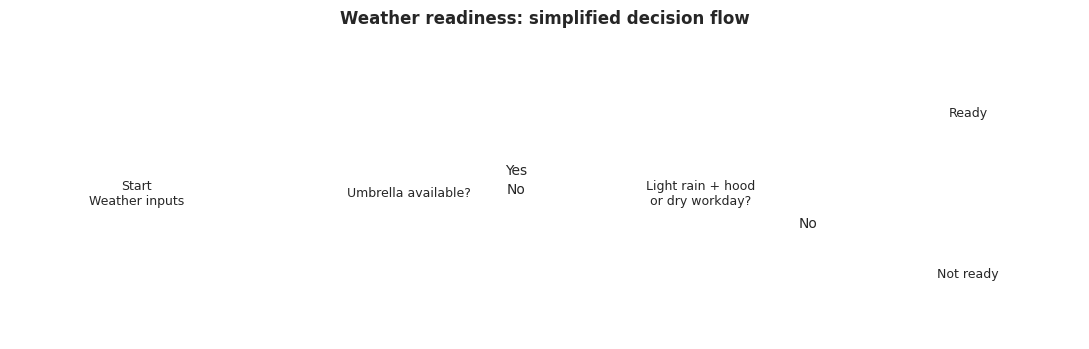

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 4); ax.axis("off")
nodes = [
    (0.3, 1.35, 2.0, 1.1, "Start\nWeather inputs"),
    (3.0, 1.35, 2.2, 1.1, "Umbrella available?"),
    (6.0, 1.35, 2.2, 1.1, "Light rain + hood\nor dry workday?"),
    (9.0, 2.45, 1.7, 1.0, "Ready"),
    (9.0, 0.35, 1.7, 1.0, "Not ready"),
]
for x,y,w,h,label in nodes:
    ax.add_patch(plt.Rectangle((x,y),w,h,fill=False,linewidth=1.8))
    ax.text(x+w/2,y+h/2,label,ha="center",va="center",fontsize=9)
ax.annotate("",xy=(3.0,1.9),xytext=(2.3,1.9),arrowprops=dict(arrowstyle="->"))
ax.annotate("No",xy=(6.0,1.9),xytext=(5.2,1.9),ha="center",arrowprops=dict(arrowstyle="->"))
ax.annotate("Yes",xy=(9.0,2.9),xytext=(5.2,2.15),ha="center",arrowprops=dict(arrowstyle="->",connectionstyle="angle3"))
ax.annotate("No",xy=(9.0,0.85),xytext=(8.2,1.45),ha="center",arrowprops=dict(arrowstyle="->",connectionstyle="angle3"))
ax.set_title("Weather readiness: simplified decision flow",weight="bold")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "weather_decision_flow.png", bbox_inches="tight")
plt.show()

## 3. Blackjack-inspired Monte Carlo simulation

This experiment compares player stand thresholds using repeated random hands. It is intentionally a **simplified educational model**: it does not model a casino shoe, betting, splits, doubles, insurance, or all table rules. Aces are adjusted from 11 to 1 as needed. The output is an estimated win percentage under these assumptions, not an optimal real-world betting strategy.

,Stand_Threshold,Estimated_Win_Rate_pct
0,12,42.03
1,13,42.37
2,14,40.98
3,15,41.53
4,16,41.45
5,17,41.43
6,18,39.22
7,19,36.83


Highest estimate in this run: threshold=13, win rate=42.37%


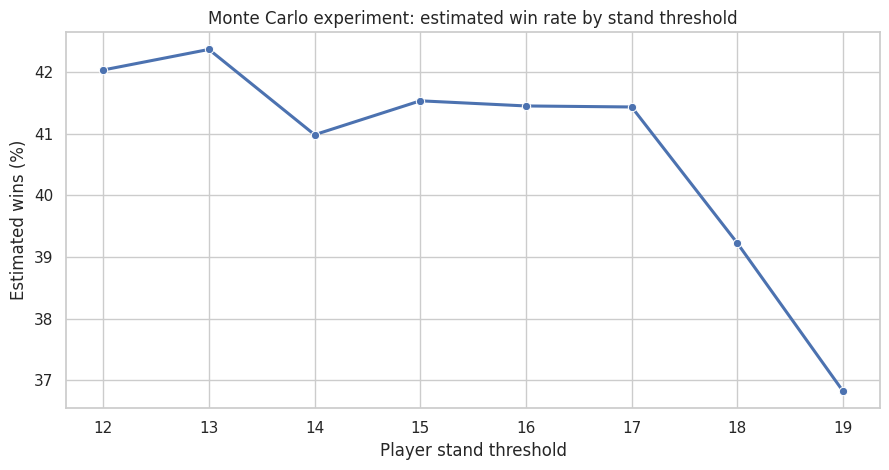

In [4]:
def hand_total(cards):
    total = sum(cards)
    aces_as_eleven = cards.count(11)
    while total > 21 and aces_as_eleven:
        total -= 10
        aces_as_eleven -= 1
    return total

def draw_card(rng):
    # Ten-valued cards represent 10, J, Q and K.
    return int(rng.choice([2,3,4,5,6,7,8,9,10,10,10,10,11]))

def simulate_blackjack(stand_threshold=16, n_trials=10000, seed=SEED):
    if not 12 <= stand_threshold <= 20:
        raise ValueError("stand_threshold must be between 12 and 20")
    if n_trials <= 0:
        raise ValueError("n_trials must be positive")
    rng = np.random.default_rng(seed + stand_threshold)
    wins = 0
    for _ in range(n_trials):
        player = [draw_card(rng), draw_card(rng)]
        dealer = [draw_card(rng)]
        while hand_total(player) < stand_threshold:
            player.append(draw_card(rng))
        player_total = hand_total(player)
        if player_total > 21:
            continue
        while hand_total(dealer) < 17:
            dealer.append(draw_card(rng))
        dealer_total = hand_total(dealer)
        if dealer_total > 21 or player_total > dealer_total:
            wins += 1
    return wins / n_trials * 100

thresholds = list(range(12, 20))
simulation_results = pd.DataFrame({
    "Stand_Threshold": thresholds,
    "Estimated_Win_Rate_pct": [simulate_blackjack(t, n_trials=12000) for t in thresholds]
})
display(simulation_results.round(2))
best_row = simulation_results.loc[simulation_results["Estimated_Win_Rate_pct"].idxmax()]
print(f"Highest estimate in this run: threshold={int(best_row.Stand_Threshold)}, "
      f"win rate={best_row.Estimated_Win_Rate_pct:.2f}%")
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.lineplot(data=simulation_results, x="Stand_Threshold", y="Estimated_Win_Rate_pct",
             marker="o", linewidth=2.2, ax=ax)
ax.set(title="Monte Carlo experiment: estimated win rate by stand threshold",
       xlabel="Player stand threshold", ylabel="Estimated wins (%)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "blackjack_simulation.png", bbox_inches="tight")
plt.show()

## 4. Data engineering with pandas

The next section demonstrates tidy tabular data, a labelled Series, growth calculations, comparison tables and CSV export. Values are illustrative and should not be treated as audited agricultural records.

In [5]:
farm_produce = pd.DataFrame({
    "Apples_crates": [65, 84, 110],
    "Bananas_bunches": [130, 115, 160],
    "Oranges_boxes": [48, 62, 75],
}, index=["2024 Actual", "2025 Actual", "2026 Forecast"])
farm_produce.index.name = "Period"
display(farm_produce)
farm_produce.to_csv(DATA_DIR / "farm_produce.csv")

bakery_recipe = pd.Series(
    ["5 cups", "2.5 cups", "4 units", "2 tsp", "300 g"],
    index=["Whole wheat flour", "Oat milk", "Eggs", "Vanilla extract", "Brown sugar"],
    name="Illustrative recipe quantities"
)
display(bakery_recipe.to_frame())

livestock = pd.DataFrame({
    "Dairy_Cows": [28, 42, 58, 72],
    "Goats": [50, 48, 65, 85],
    "Sheep": [20, 30, 42, 60],
}, index=["Year 1", "Year 2", "Year 3", "Year 4"])
livestock.index.name = "Period"
livestock.to_csv(DATA_DIR / "livestock_growth_record.csv")

livestock_change = livestock.pct_change() * 100
livestock_comparison = pd.DataFrame({
    "Year_1": livestock.iloc[0],
    "Year_4": livestock.iloc[-1],
    "Absolute_Change": livestock.iloc[-1] - livestock.iloc[0],
    "Percentage_Change": (livestock.iloc[-1] / livestock.iloc[0] - 1) * 100
})
display(livestock_comparison.round(2))

,Apples_crates,Bananas_bunches,Oranges_boxes
Period,,,
2024 Actual,65,130,48
2025 Actual,84,115,62
2026 Forecast,110,160,75


,Illustrative recipe quantities
Whole wheat flour,5 cups
Oat milk,2.5 cups
Eggs,4 units
Vanilla extract,2 tsp
Brown sugar,300 g


,Year_1,Year_4,Absolute_Change,Percentage_Change
Dairy_Cows,28,72,44,157.14
Goats,50,85,35,70.00
Sheep,20,60,40,200.00


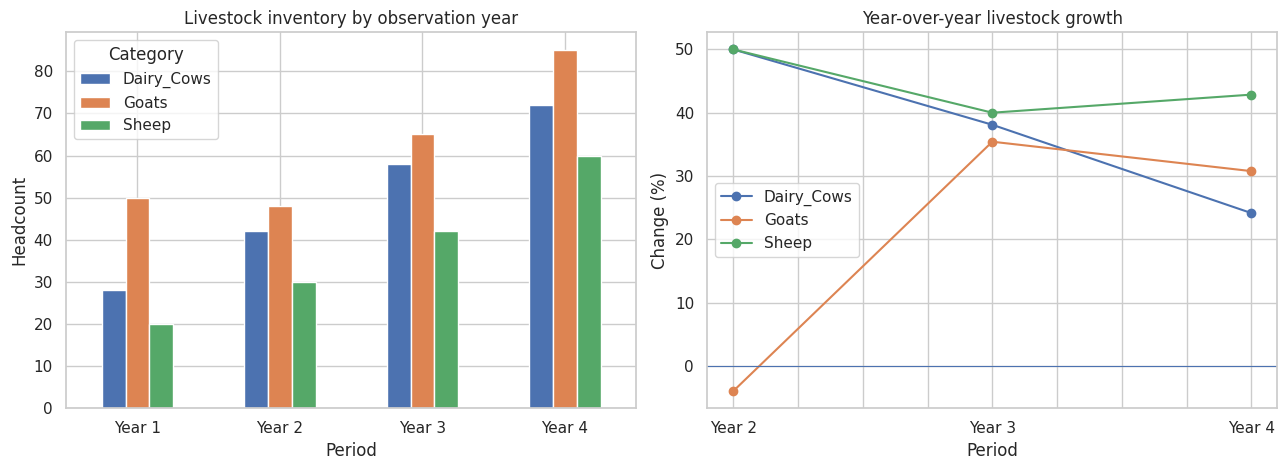

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
livestock.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set(title="Livestock inventory by observation year", xlabel="Period", ylabel="Headcount")
axes[0].legend(title="Category")
livestock_change.iloc[1:].plot(kind="line", marker="o", ax=axes[1])
axes[1].set(title="Year-over-year livestock growth", xlabel="Period", ylabel="Change (%)")
axes[1].axhline(0, linewidth=0.8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "livestock_growth_comparison.png", bbox_inches="tight")
plt.show()

## 5. Synthetic housing dataset and data-quality checks

A reproducible dataset of 1,460 synthetic property records is generated. Feature relationships are deliberately constructed for analysis practice. Because the data is synthetic, the resulting associations are illustrative and do not establish real-world causal relationships.

In [7]:
rng = np.random.default_rng(SEED)
n_samples = 1460
year_built = rng.integers(1955, 2025, size=n_samples)
house_age = 2026 - year_built
lot_area = rng.normal(10450, 3100, n_samples).clip(2600).astype(int)
overall_quality = rng.integers(3, 11, size=n_samples)
living_area = (lot_area * 0.11 + overall_quality * 175
               + rng.normal(300, 140, n_samples)).clip(450).astype(int)
sale_price = (living_area * 118 + overall_quality * 19500
              - house_age * 420 + rng.normal(0, 16000, n_samples)).clip(65000).astype(int)

housing = pd.DataFrame({
    "LotArea_sqft": lot_area,
    "YearBuilt": year_built,
    "HouseAge_years": house_age,
    "OverallQual": overall_quality,
    "GrLivArea_sqft": living_area,
    "SalePrice_USD": sale_price,
})
housing.to_csv(DATA_DIR / "housing_profile_dataset.csv", index=False)

quality_report = pd.DataFrame({
    "Check": ["Rows", "Columns", "Duplicate rows", "Missing cells", "Minimum sale price", "Maximum sale price"],
    "Result": [len(housing), housing.shape[1], int(housing.duplicated().sum()),
               int(housing.isna().sum().sum()), int(housing.SalePrice_USD.min()),
               int(housing.SalePrice_USD.max())]
})
display(housing.head())
display(quality_report)
assert housing.isna().sum().sum() == 0
assert (housing["SalePrice_USD"] > 0).all()

,LotArea_sqft,YearBuilt,HouseAge_years,OverallQual,GrLivArea_sqft,SalePrice_USD
0,13900,1961,65,6,2613,414378
1,9690,2009,17,4,2082,325773
2,7254,2000,26,8,2183,388994
3,10273,1985,41,3,1769,252447
4,13702,1985,41,8,3132,500821


,Check,Result
0,Rows,1460
1,Columns,6
2,Duplicate rows,0
3,Missing cells,0
4,Minimum sale price,148968
5,Maximum sale price,665123


## 6. Exploratory data analysis

### 6.1 Descriptive statistics and grouped comparison

The summary table provides central tendency and spread. The grouped table compares synthetic sale prices by overall quality rating.

In [8]:
summary_stats = housing.describe().T.rename(columns={"50%": "median"})
display(summary_stats.round(2))

quality_comparison = housing.groupby("OverallQual")["SalePrice_USD"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)
display(quality_comparison)

corr_with_price = housing.corr(numeric_only=True)["SalePrice_USD"].drop("SalePrice_USD").sort_values(ascending=False)
display(corr_with_price.rename("Pearson correlation with sale price").to_frame())

,count,mean,std,min,25%,median,75%,max
LotArea_sqft,1460.0,10291.47,3085.00,2600.0,8237.00,10444.5,12334.25,20304.0
YearBuilt,1460.0,1990.02,20.22,1955.0,1973.00,1990.0,2008.00,2024.0
HouseAge_years,1460.0,35.98,20.22,2.0,18.00,36.0,53.00,71.0
OverallQual,1460.0,6.49,2.28,3.0,5.00,7.0,8.00,10.0
GrLivArea_sqft,1460.0,2569.73,536.69,996.0,2193.75,2575.5,2957.25,4011.0
SalePrice_USD,1460.0,414466.75,102129.62,148968.0,339277.75,414447.5,494271.00,665123.0


,count,mean,median,std,min,max
OverallQual,,,,,,
3,189,269858.11,267421.0,45642.63,148968,392127
4,169,318329.89,321229.0,46057.41,177116,427991
5,180,355763.17,357392.0,46325.17,223194,502617
6,186,401528.49,399613.0,43571.78,252723,498611
7,207,433216.38,434723.0,50763.55,316040,595154
8,165,469063.15,466756.0,45435.77,371948,566966
9,192,514595.79,513726.0,46507.55,390726,659313
10,172,556542.15,557763.0,43594.48,413412,665123


,Pearson correlation with sale price
GrLivArea_sqft,0.937941
OverallQual,0.891886
LotArea_sqft,0.389058
YearBuilt,0.097334
HouseAge_years,-0.097334


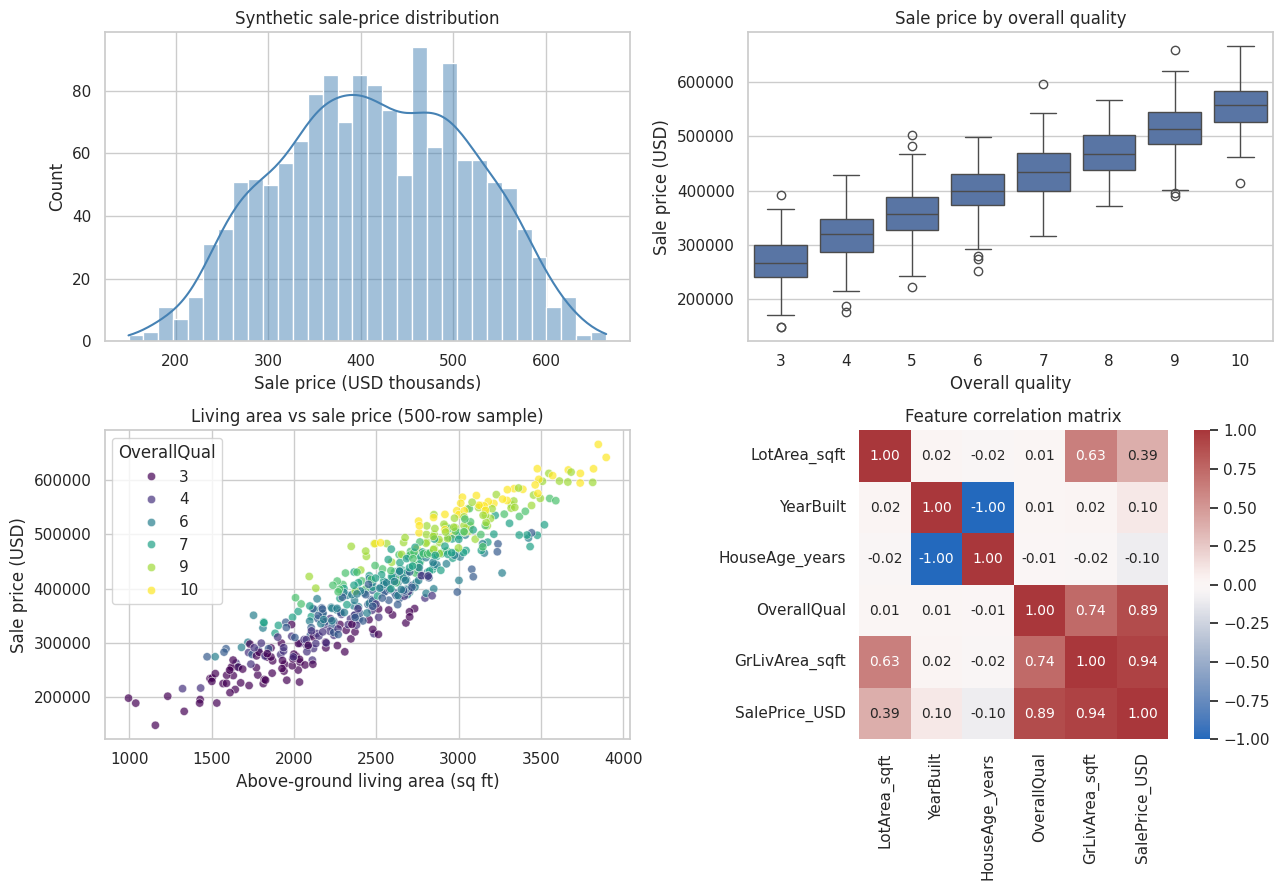

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(housing["SalePrice_USD"] / 1000, bins=32, kde=True, color="steelblue", ax=axes[0, 0])
axes[0, 0].set(title="Synthetic sale-price distribution", xlabel="Sale price (USD thousands)")
sns.boxplot(data=housing, x="OverallQual", y="SalePrice_USD", ax=axes[0, 1])
axes[0, 1].set(title="Sale price by overall quality", xlabel="Overall quality", ylabel="Sale price (USD)")
sns.scatterplot(data=housing.sample(500, random_state=SEED), x="GrLivArea_sqft",
                y="SalePrice_USD", hue="OverallQual", palette="viridis", alpha=.7, ax=axes[1, 0])
axes[1, 0].set(title="Living area vs sale price (500-row sample)",
               xlabel="Above-ground living area (sq ft)", ylabel="Sale price (USD)")
sns.heatmap(housing.corr(numeric_only=True), annot=True, fmt=".2f", cmap="vlag",
            center=0, square=True, ax=axes[1, 1])
axes[1, 1].set_title("Feature correlation matrix")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "housing_eda_dashboard.png", bbox_inches="tight")
plt.show()

### 6.2 Key findings (descriptive, not causal)

The following statements are calculated from the generated sample. Re-run the notebook after changing the seed or data-generation assumptions to see how they change.

In [10]:
key_metrics = pd.Series({
    "Number of properties": len(housing),
    "Average sale price (USD)": housing["SalePrice_USD"].mean(),
    "Median sale price (USD)": housing["SalePrice_USD"].median(),
    "Average lot area (sq ft)": housing["LotArea_sqft"].mean(),
    "Average living area (sq ft)": housing["GrLivArea_sqft"].mean(),
    "Average house age (years)": housing["HouseAge_years"].mean(),
    "Sale-price / living-area correlation": housing["SalePrice_USD"].corr(housing["GrLivArea_sqft"]),
    "Sale-price / quality correlation": housing["SalePrice_USD"].corr(housing["OverallQual"]),
})
display(key_metrics.to_frame("Value").round(2))

,Value
Number of properties,1460.00
Average sale price (USD),414466.75
Median sale price (USD),414447.50
Average lot area (sq ft),10291.47
Average living area (sq ft),2569.73
Average house age (years),35.98
Sale-price / living-area correlation,0.94
Sale-price / quality correlation,0.89


## 7. Interpretation, limitations and next steps

### What this project demonstrates
- Reusable functions, input validation, boolean decision logic and simulation.
- Pandas-based data construction, transformation, aggregation and CSV export.
- Reproducible synthetic data generation and basic data-quality assertions.
- Comparative analysis using summary tables, grouped statistics and multiple chart types.
- Communication of assumptions and limitations alongside visual results.

### Important limitations
- All included datasets are synthetic or illustrative; no external data source is claimed.
- The blackjack model is simplified and is not a casino-grade simulator.
- Correlation measures linear association and does not prove causation.
- The housing generator encodes relationships by design; findings cannot be generalized to actual property markets.

### Suggested professional extensions
1. Add automated tests with `pytest` for functions and data-quality rules.
2. Replace synthetic data with a documented, licensed real dataset.
3. Add a modelling stage with train/test split, baseline regression and error metrics.
4. Add a data dictionary and a reproducible environment lock file.
5. Set up GitHub Actions to execute notebook checks on every push.

## 8. Exported artefacts

The notebook writes CSV datasets to `data/` and PNG figures to `figures/`. The README documents setup, execution, repository structure and responsible interpretation.

In [11]:
# Export a compact machine-readable summary for the repository.
summary_stats.to_csv(REPORTS_DIR / "housing_summary_statistics.csv")
quality_comparison.to_csv(REPORTS_DIR / "housing_quality_comparison.csv")
simulation_results.to_csv(REPORTS_DIR / "blackjack_simulation_results.csv", index=False)

print("Export complete:")
for folder in (DATA_DIR, FIGURES_DIR, REPORTS_DIR):
    for item in sorted(folder.glob("*")):
        print(" -", item.relative_to(PROJECT_ROOT))

Export complete:
 - data/farm_produce.csv
 - data/housing_profile_dataset.csv
 - data/livestock_growth_record.csv
 - figures/blackjack_simulation.png
 - figures/housing_eda_dashboard.png
 - figures/livestock_growth_comparison.png
 - figures/weather_decision_flow.png
 - reports/blackjack_simulation_results.csv
 - reports/housing_quality_comparison.csv
 - reports/housing_summary_statistics.csv


---
**Author: HARPREET SINGH**  
*Portfolio project — Integrated Data Science Pipeline*